# 02 · Retention — How much of the Big 4 footprint stays in the region?

**NC3 · Lansing Economic Ecosystem and Community Wealth Analysis** — working notebook (wangz153)

Notebook 01 measured *how big* each institution is. This notebook asks *how much of that activity stays local*. Money leaves an institution through three channels, and each is measured separately:

| Channel | Indicator | Question | Main data |
|---|---|---|---|
| **Wages** (private) | W1 local resident capture | What share of the institution's workers live in the region? | ACS 2016–2020 commuting flows; LODES 2021 block OD |
| | W2 payroll leakage | How many payroll dollars go to workers living outside the region? | W1 × payroll from notebook 01 |
| **Suppliers** (private) | GM local supply chain | How many local auto-parts jobs sit alongside GM's own jobs? | QCEW 336 / 3361 / 3363 |
| **Taxes** (public) | T2 / T3 GM property tax and abatements | What does GM pay in property tax, and what is abated? | City of Lansing parcel records; ACFR Table 7 |
| | T4 city income tax | How much city income tax do Big 4 workers generate? | W1 residency × payroll × statutory rates |
| *Context* | Household wealth flows | Is the region gaining or losing household income through migration? | IRS SOI county migration |

**Definitions** (same as notebook 01): region = Clinton, Eaton, Ingham counties. Every estimate is a **range**; section 7 tests which conclusions hold across the range.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nc3_helpers import *

pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:,.2f}")
OUT_DIR = Path.cwd() / "outputs"; OUT_DIR.mkdir(exist_ok=True)

od = load_lodes_od()                 # LODES 2021, workplace block x residence
acs = load_acs_flows()               # ACS 2016-2020 county flows
footprint = pd.read_csv(OUT_DIR / "footprint_v0_2025.csv", index_col="institution")   # from notebook 01
parcel_vals, parcel_bills = load_parcels()
taxpayers = load_acfr_taxpayers()
qcew = load_qcew()
print(f"LODES jobs with workplace in region: {od.S000.sum():,.0f} | ACS workers working in region: {acs[acs.work_fips.isin(TRI_FIPS)].workers.sum():,.0f}")

LODES jobs with workplace in region: 232,664 | ACS workers working in region: 244,105


## 1. Data checks — is LODES telling the truth about where workers live?

LODES assigns each job a home address from administrative records. A known weakness: a large employer can report many workers at one address. A single block that holds thousands of jobs whose workers mostly live far away is a red flag. Rule used here: **any block with more than 2,000 jobs and fewer than 25% of workers living in the region is flagged and excluded.**

In [2]:
blocks = (od.groupby(["w_geocode", "w_county", "w_lat", "w_lon"], dropna=False)
            .apply(lambda g: pd.Series({"jobs": g.S000.sum(),
                                        "local_pct": g.loc[g.h_in_region, "S000"].sum() / g.S000.sum() * 100,
                                        "detroit_metro_pct": g.loc[g.h_county.isin(["26163","26125","26099"]), "S000"].sum() / g.S000.sum() * 100,
                                        "high_earn_pct": g.SE03.sum() / g.S000.sum() * 100}),
                   include_groups=False)
            .reset_index())
flagged = blocks[(blocks.jobs > 2000) & (blocks.local_pct < 25)]
ANOMALY_BLOCKS = set(flagged.w_geocode)
od["anomaly"] = od.w_geocode.isin(ANOMALY_BLOCKS)
print("Flagged blocks:", len(flagged))
pd.concat([flagged.assign(note="FLAGGED"),
           blocks.sort_values("jobs", ascending=False).head(6).assign(note="largest blocks for comparison")]).drop_duplicates("w_geocode")

Flagged blocks: 2


,w_geocode,w_county,w_lat,w_lon,jobs,local_pct,detroit_metro_pct,high_earn_pct,note
1778,260650041003004,26065,42.74,-84.48,"4,902",18.50,42.90,54.45,FLAGGED
2791,260650067002006,26065,42.73,-84.56,"22,101",9.03,51.93,4.12,FLAGGED
2857,260659800001075,26065,42.72,-84.49,"12,696",71.99,4.34,75.95,largest blocks for comparison
2679,260650065003001,26065,42.73,-84.54,"8,077",77.53,2.43,72.30,largest blocks for comparison
667,260450202012008,26045,42.72,-84.64,"3,579",70.72,3.19,89.52,largest blocks for comparison
2120,260650053043018,26065,42.67,-84.53,"3,552",66.33,8.14,64.02,largest blocks for comparison


**Reading the check.** Two blocks are flagged. A downtown Lansing block holds about 22,000 jobs, yet fewer than 1 in 10 of its workers live in the region, about half live in metro Detroit, and very few earn over $3,333 a month — a real workplace does not look like that. The most likely explanation is a statewide, low-wage workforce administratively attached to a Lansing address. A second East Lansing block (about 4,900 jobs, under 20% local) shows the same pattern at smaller scale. Both are hypotheses — LODES does not name employers. Every other large block — MSU's campus, the hospital, insurers — has 65%+ local workers. Flagged blocks are excluded below; the raw figure is kept for transparency.

## 2. W1 — Local resident capture

### 2a. Region level: two sources

ACS asks workers where they live (survey). LODES uses administrative addresses. They answer the same question differently, so both are shown.

In [3]:
rows = []
for fips, county in TRI_COUNTY.items():
    a = acs[acs.work_fips == fips]
    o = od[od.w_county == fips]
    rows.append({
        "workplace county": county,
        "ACS: same county %": a.loc[a.res_fips == fips, "workers"].sum() / a.workers.sum() * 100,
        "ACS: in region %": a.loc[a.res_in_region, "workers"].sum() / a.workers.sum() * 100,
        "LODES raw: in region %": share(o, "h_in_region"),
        "LODES excl. flagged: in region %": share(o[~o.anomaly], "h_in_region"),
    })
w1_region = pd.DataFrame(rows).set_index("workplace county")
a_all = acs[acs.work_fips.isin(TRI_FIPS)]
w1_region.loc["Region (3 counties)"] = [np.nan,
    a_all.loc[a_all.res_in_region, "workers"].sum() / a_all.workers.sum() * 100,
    share(od, "h_in_region"), share(od[~od.anomaly], "h_in_region")]
# Calibration factor per county: how much LODES understates local residence relative to ACS
# Calibration: how much LODES overstates the NON-local share relative to ACS
w1_region["non-local ratio (ACS / LODES)"] = (100 - w1_region["ACS: in region %"]) / (100 - w1_region["LODES excl. flagged: in region %"])
w1_region

,ACS: same county %,ACS: in region %,LODES raw: in region %,LODES excl. flagged: in region %,non-local ratio (ACS / LODES)
workplace county,,,,,
Ingham,64.27,85.72,53.35,61.56,0.37
Eaton,50.94,85.07,58.21,58.21,0.36
Clinton,57.03,83.01,63.21,63.21,0.46
Region (3 counties),NaN,85.32,55.14,60.97,0.38


### 2b. Institution level: LODES block footprints

LODES has workplace coordinates, so institution footprints can be drawn from blocks. Each footprint is checked against the employment range from notebook 01.

| Institution | Footprint | Check against notebook 01 |
|---|---|---|
| MSU | Census tract 9800 (campus special tract), East Lansing | Should fall in 10,253–17,351 |
| State Government | Downtown Lansing tract 0067 (Capitol complex), **excluding** the flagged block | Mixed: also holds city, county and private downtown jobs |
| GM | Lansing Delta Township Assembly block + tract 9802 (Lansing Grand River Assembly) | Should be near GM's ~4,500 |
| Local Government | No single footprint (offices spread across the region) | Uses the region-level figure |

LODES overstates the *non*-local share (section 2a), so each institution gets two values:
- **Low end** = raw LODES share living in the region.
- **High end (ACS-calibrated)** = 100% − (raw non-local share × the county's ACS/LODES non-local ratio). Scaling the non-local share, rather than the local share, keeps the estimate below 100% and shrinks leakage in proportion to how much LODES overstates it in that county.

In [4]:
FOOTPRINTS = {
    "MSU":              (od.w_tract11 == "26065980000"),
    "State Government": (od.w_tract11 == "26065006700") & ~od.anomaly,
    "GM":               od.w_geocode.isin(["260450203024018"]) | (od.w_tract11 == "26065980200"),
}
CITY_OF_WORK = {"MSU": "East Lansing city, MI", "State Government": "Lansing city, MI", "GM": "Lansing city, MI"}
ratio = w1_region["non-local ratio (ACS / LODES)"]

rows = []
for inst, mask in FOOTPRINTS.items():
    f = od[mask]
    # county-specific calibration, weighted by where the footprint's jobs are
    rat = sum(f.loc[f.w_county == fips, "S000"].sum() * ratio[c] for fips, c in TRI_COUNTY.items()) / f.S000.sum()
    raw = share(f, "h_in_region")
    cal = 100 - (100 - raw) * rat
    city_res = f.loc[f.h_place == CITY_OF_WORK[inst], "S000"].sum() / f.S000.sum() * 100
    rows.append({"institution": inst, "footprint_jobs_2021": f.S000.sum(),
                 "W1 low (LODES raw) %": raw, "W1 high (ACS-calibrated) %": cal,
                 "lives in city of work (LODES) %": city_res,
                 "lives in city of work (calibrated) %": city_res * cal / raw,
                 "high earners (SE03) %": f.SE03.sum() / f.S000.sum() * 100})
reg = w1_region.loc["Region (3 counties)"]
rows.append({"institution": "Local Government", "footprint_jobs_2021": np.nan,
             "W1 low (LODES raw) %": reg["LODES excl. flagged: in region %"], "W1 high (ACS-calibrated) %": reg["ACS: in region %"],
             "lives in city of work (LODES) %": np.nan, "lives in city of work (calibrated) %": np.nan, "high earners (SE03) %": np.nan})
w1 = pd.DataFrame(rows).set_index("institution").reindex(BIG4)
w1.join(footprint[["low", "high"]].rename(columns={"low": "nb01 low", "high": "nb01 high"}))

,footprint_jobs_2021,W1 low (LODES raw) %,W1 high (ACS-calibrated) %,lives in city of work (LODES) %,lives in city of work (calibrated) %,high earners (SE03) %,nb01 low,nb01 high
institution,,,,,,,,
MSU,"13,851",70.09,88.88,10.27,13.02,76.04,"10,253","17,351"
GM,"3,666",42.42,79.09,11.95,22.28,82.24,"4,549","6,383"
State Government,"19,413",49.29,81.15,11.65,19.19,89.57,"13,880","16,416"
Local Government,NaN,60.97,85.32,NaN,NaN,NaN,"6,298","18,910"


### Chart — Share of workers living in the region

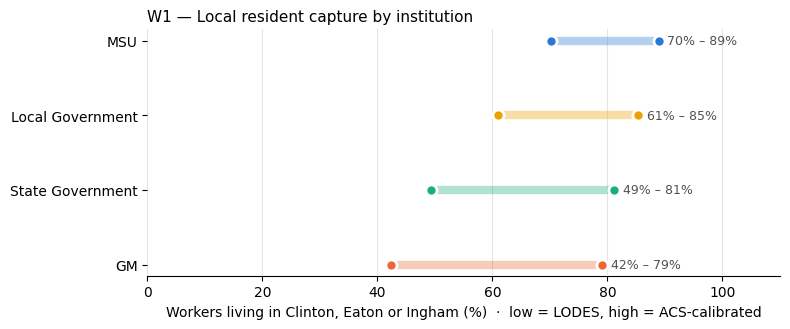

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
order = w1.sort_values("W1 high (ACS-calibrated) %").index
for i, inst in enumerate(order):
    lo, hi = w1.loc[inst, ["W1 low (LODES raw) %", "W1 high (ACS-calibrated) %"]]
    c = BIG4_COLORS[inst]
    ax.plot([lo, hi], [i, i], color=c, lw=6, alpha=0.35, solid_capstyle="round")
    ax.plot([lo, hi], [i, i], "o", color=c, ms=8, mec="white", mew=2)
    ax.text(hi + 1.5, i, f"{lo:.0f}% – {hi:.0f}%", va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(order)), order); ax.set_xlim(0, 110)
ax.set_xlabel("Workers living in Clinton, Eaton or Ingham (%)  ·  low = LODES, high = ACS-calibrated")
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.set_title("W1 — Local resident capture by institution", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 3. W2 — Payroll leakage

Payroll comes from notebook 01 (jobs × average annual pay, 2025). Leakage = payroll × (1 − W1).
- **Low leakage** = low payroll × (1 − high W1)
- **High leakage** = high payroll × (1 − low W1)

Mixing 2025 payroll with 2016–2021 commuting shares assumes commuting patterns changed little; this is stated as a limitation.

In [6]:
pay = footprint["avg_annual_pay"]
w2 = pd.DataFrame({
    "payroll low ($M)":  footprint["low"]  * pay / 1e6,
    "payroll high ($M)": footprint["high"] * pay / 1e6,
}).reindex(BIG4)
w2["leakage low ($M)"]  = w2["payroll low ($M)"]  * (1 - w1["W1 high (ACS-calibrated) %"] / 100)
w2["leakage high ($M)"] = w2["payroll high ($M)"] * (1 - w1["W1 low (LODES raw) %"] / 100)
w2["leakage share low %"]  = w2["leakage low ($M)"]  / w2["payroll low ($M)"]  * 100
w2["leakage share high %"] = w2["leakage high ($M)"] / w2["payroll high ($M)"] * 100
w2.loc["Big 4 total"] = w2.sum(numeric_only=True)
w2.loc["Big 4 total", ["leakage share low %", "leakage share high %"]] = [
    w2.loc["Big 4 total", "leakage low ($M)"] / w2.loc["Big 4 total", "payroll low ($M)"] * 100,
    w2.loc["Big 4 total", "leakage high ($M)"] / w2.loc["Big 4 total", "payroll high ($M)"] * 100]
w2

,payroll low ($M),payroll high ($M),leakage low ($M),leakage high ($M),leakage share low %,leakage share high %
institution,,,,,,
MSU,925,"1,566",103,468,11.12,29.91
GM,458,643,95.86,370,20.91,57.58
State Government,"1,271","1,503",240,762,18.85,50.71
Local Government,406,"1,220",59.63,476,14.68,39.03
Big 4 total,"3,061","4,933",498,"2,077",16.26,42.12


## 4. GM local supply chain

QCEW publishes motor-vehicle **parts** suppliers (NAICS 3363) for Ingham County every year. Two views:
- **Ingham ratio**: Ingham 3363 jobs per 100 GM jobs in Ingham (GM Ingham = 336 − 3363 residual from notebook 01).
- **Region cluster**: all transportation-equipment jobs (336) beyond GM's own estimate, per 100 GM jobs (Eaton 3363 is suppressed, so this is the only region-wide view).

In [7]:
cell = lambda own, ind: qcew_cell(qcew, own, ind)
ing_3363 = cell(OWN_PRIVATE, "3363")["Ingham"]
ing_gm   = cell(OWN_PRIVATE, "336")["Ingham"] - ing_3363
eaton_gm = cell(OWN_PRIVATE, "3361")["Eaton"]
cluster  = tri_county_sum(cell(OWN_PRIVATE, "336"))
gm_est   = eaton_gm + ing_gm
supply = pd.DataFrame({
    "Ingham parts suppliers (3363)": ing_3363,
    "GM Ingham est.": ing_gm,
    "Ingham supplier jobs per 100 GM jobs": ing_3363 / ing_gm * 100,
    "Region 336 cluster": cluster,
    "GM est. (region)": gm_est,
    "Other 336 jobs per 100 GM jobs": (cluster - gm_est) / gm_est * 100,
})
supply

,Ingham parts suppliers (3363),GM Ingham est.,Ingham supplier jobs per 100 GM jobs,Region 336 cluster,GM est. (region),Other 336 jobs per 100 GM jobs
year,,,,,,
2019,"1,075","2,713",39.62,"7,233",NaN,NaN
2020,404,"2,232",18.10,"6,298",NaN,NaN
2021,"1,597","1,931",82.70,"7,628","5,058",50.81
2022,"2,055","2,305",89.15,"9,053","5,773",56.82
2023,"1,956","2,385",82.01,"8,933","5,835",53.09
2024,"1,505","2,010",74.88,"8,701","6,188",40.61
2025,"1,764","1,951",90.42,"9,298","6,383",45.67


## 5. Tax channel

### 5a. GM property tax in the City of Lansing (2025)

Both GM plants are taxed by the City of Lansing — Grand River directly, Delta Township Assembly through the Lansing–Delta Township PA 425 agreement. Parcel records were collected for the Delta plant, all three IFT-abated buildings, and GM's personal-property accounts. GM's Grand River real property (owner name "General Motors Co.") is taken from ACFR Table 7 and its tax is **estimated** at the Ingham-side full rate (twice the rate observed on GM's Ingham IFT parcels, since IFT buildings pay half).

In [8]:
Y = 2025
vals = parcel_vals[parcel_vals.tax_year == Y].set_index("parcel")
bills = parcel_bills[parcel_bills.tax_year == Y].groupby("parcel").total_tax_billed.sum()
gm = vals[vals.big4_flag == "GM"].copy()
gm["tax_billed"] = bills.reindex(gm.index).fillna(0)
gm["component"] = np.select(
    [gm.property_class.str.startswith("351"), gm.index.str.startswith("95-")],
    ["Personal property (equipment)", "IFT-abated building (half rate)"], "Real property, full rate")

FULL_MILLS = gm.loc["23-50-40-33-101-002", "tax_billed"] / gm.loc["23-50-40-33-101-002", "taxable_value"] * 1000   # Eaton side (Grand Ledge schools)
ing_ift = gm[gm.index.str.startswith("95-33")]
FULL_MILLS_INGHAM = 2 * ing_ift.tax_billed.sum() / ing_ift.taxable_value.sum() * 1000                         # Ingham side: IFT = half rate
GM_CO_T7 = taxpayers.query("tax_year == 2025 and taxpayer == 'General Motors Co.'").taxable_assessed_value.iloc[0]
GM_LLC_T7 = taxpayers.query("tax_year == 2025 and taxpayer == 'General Motors LLC'").taxable_assessed_value.iloc[0]

t2 = gm.groupby("component").agg(parcels=("taxable_value", "size"), taxable_value=("taxable_value", "sum"),
                                 tax_billed=("tax_billed", "sum"))
t2.loc["Grand River real property (ACFR T7, tax estimated)"] = [np.nan, GM_CO_T7, GM_CO_T7 * FULL_MILLS_INGHAM / 1000]
t2.loc["GM total"] = t2.sum()
print(f"Full-rate millage, {Y}: Eaton side (Delta plant, observed) {FULL_MILLS:.1f} mills | Ingham side (2 x IFT rate) {FULL_MILLS_INGHAM:.1f} mills")
print(f"GM LLC parcels collected explain {gm.taxable_value.sum() / GM_LLC_T7:.0%} of ACFR Table 7 'General Motors LLC' ({GM_LLC_T7:,.0f})")
t2

Full-rate millage, 2025: Eaton side (Delta plant, observed) 77.1 mills | Ingham side (2 x IFT rate) 87.0 mills
GM LLC parcels collected explain 89% of ACFR Table 7 'General Motors LLC' (49,069,602)


,parcels,taxable_value,tax_billed
component,,,
IFT-abated building (half rate),3.00,"9,614,557","410,034"
Personal property (equipment),3.00,"84,400","4,829"
"Real property, full rate",1.00,"34,057,732","2,626,981"
"Grand River real property (ACFR T7, tax estimated)",NaN,"19,921,817","1,732,263"
GM total,7.00,"63,678,506","4,774,108"


### 5b. What is abated or exempt?

- **IFT abatements (GM):** IFT buildings pay roughly half the normal millage, so the tax forgone is approximately equal to the tax billed on those parcels. Certificates expire 2027–2028.
- **Equipment (GM):** eligible manufacturing personal property is exempt under Michigan law; GM's plant-equipment accounts show $0 taxable. The foregone amount cannot be estimated from these records (no value is shown), so it is listed as a data gap. This is a statewide policy, not a GM-specific deal.
- **Contrast — LG Energy Solution battery plant (former GM joint venture, *not* GM):** Renaissance Zone through 2040. Counterfactual = its taxable value × the full-rate millage on the neighbouring GM plant.

In [9]:
ift_billed = t2.loc["IFT-abated building (half rate)", "tax_billed"]
lges = parcel_vals[(parcel_vals.tax_year == Y) & parcel_vals.owner.str.contains("LG ENERGY")].iloc[0]
lges_billed = parcel_bills[(parcel_bills.parcel == lges.parcel) & (parcel_bills.tax_year == Y)].total_tax_billed.sum()
lges_full = lges.taxable_value * FULL_MILLS / 1000
t3 = pd.DataFrame({
    "tax billed ($)": [ift_billed, lges_billed],
    "full-rate counterfactual ($)": [ift_billed * 2, lges_full],
}, index=["GM IFT buildings (3 parcels)", "LGES battery plant (Renaissance Zone) — not GM"])
t3["forgone ($)"] = t3["full-rate counterfactual ($)"] - t3["tax billed ($)"]
t3["share forgone %"] = t3["forgone ($)"] / t3["full-rate counterfactual ($)"] * 100
t3

,tax billed ($),full-rate counterfactual ($),forgone ($),share forgone %
GM IFT buildings (3 parcels),"410,034","820,069","410,034",50.00
LGES battery plant (Renaissance Zone) — not GM,"458,316","6,749,221","6,290,904",93.21


### 5c. T4 — City income tax generated by Big 4 workers

Lansing and East Lansing both tax residents at 1% and non-residents at 0.5% of wages earned in the city. Estimate = payroll × (resident share × 1% + non-resident share × 0.5%). Residency comes from the LODES footprints (low) and the ACS-calibrated share (high).

Benchmark: City of Lansing income tax revenue, FY ended June 30, 2025 = **$45,379,062** (ACFR, government-wide statement). GM Delta Township Assembly workers pay Lansing income tax under the PA 425 agreement, with revenue shared with Delta Township.

In [10]:
LANSING_INCOME_TAX_FY2025 = 45_379_062  # City of Lansing ACFR FY2025, MD&A (government-wide)
def city_tax(payroll, resident_pct):
    r = resident_pct / 100
    return payroll * (r * 0.01 + (1 - r) * 0.005)

t4 = pd.DataFrame(index=["MSU", "GM", "State Government"])
t4["city"] = ["East Lansing", "Lansing", "Lansing"]
t4["tax low ($M)"]  = [city_tax(w2.loc[i, "payroll low ($M)"],  w1.loc[i, "lives in city of work (LODES) %"])     for i in t4.index]
t4["tax high ($M)"] = [city_tax(w2.loc[i, "payroll high ($M)"], w1.loc[i, "lives in city of work (calibrated) %"]) for i in t4.index]
lansing = t4[t4.city == "Lansing"][["tax low ($M)", "tax high ($M)"]].sum()
t4.loc["GM + State, share of Lansing income tax"] = ["Lansing",
    lansing["tax low ($M)"] / (LANSING_INCOME_TAX_FY2025 / 1e6) * 100,
    lansing["tax high ($M)"] / (LANSING_INCOME_TAX_FY2025 / 1e6) * 100]
t4

,city,tax low ($M),tax high ($M)
MSU,East Lansing,5.10,8.85
GM,Lansing,2.57,3.93
State Government,Lansing,7.10,8.96
"GM + State, share of Lansing income tax",Lansing,21.29,28.41


*Note: the last row is a percentage, not dollars. State Government payroll here covers state jobs across the region, not only those inside Lansing city limits, so the high end is an upper bound.*

## 6. Context — household income flows through migration (IRS, 2022–23)

IRS migration data track tax returns that changed county between filing years, with the adjusted gross income (AGI) they carried. This is regional context, not attributable to any institution.

In [11]:
irs = load_irs_migration()
for c in ["n1", "n2", "agi"]:
    irs[c] = pd.to_numeric(irs[c], errors="coerce")
inflow  = irs[(irs.direction == "inflow")  & (irs.y1_statefips == "96")].set_index("county_name")
outflow = irs[(irs.direction == "outflow") & (irs.y2_statefips == "96")].set_index("county_name")
mig = pd.DataFrame({
    "returns in": inflow.n1, "returns out": outflow.n1,
    "AGI in ($M)": inflow.agi / 1e3, "AGI out ($M)": outflow.agi / 1e3,
})
mig["net returns"] = mig["returns in"] - mig["returns out"]
mig["net AGI ($M)"] = mig["AGI in ($M)"] - mig["AGI out ($M)"]
mig["avg AGI in ($K)"]  = mig["AGI in ($M)"]  / mig["returns in"]  * 1e3
mig["avg AGI out ($K)"] = mig["AGI out ($M)"] / mig["returns out"] * 1e3
mig.loc["Region (sum of counties)*"] = mig.sum(numeric_only=True)
mig.loc["Region (sum of counties)*", ["avg AGI in ($K)", "avg AGI out ($K)"]] = np.nan
mig

,returns in,returns out,AGI in ($M),AGI out ($M),net returns,net AGI ($M),avg AGI in ($K),avg AGI out ($K)
county_name,,,,,,,,
Clinton,"2,610","2,672",158,159,-62.00,-0.31,60.65,59.36
Eaton,"3,711","3,770",190,205,-59.00,-14.82,51.18,54.31
Ingham,"8,474","9,090",404,529,-616,-125,47.71,58.20
Region (sum of counties)*,"14,795","15,532",753,892,-737,-140,NaN,NaN


*\*Summing counties double-counts moves between the three counties (a move from Ingham to Eaton is an outflow for one and an inflow for the other), so the regional net is approximate.*

## 7. Robustness — which conclusions hold across the range?

Same rule as notebook 01: a conclusion is **Robust** only if it holds at both ends of the range.

In [12]:
def verdict(a, b): return "Robust" if (a and b) else "Not supported"
R = []
reg_lo, reg_hi = w1_region.loc["Region (3 counties)", ["LODES excl. flagged: in region %", "ACS: in region %"]]
R.append(("W1", "Most regional jobs are held by regional residents (>50%)", f"{reg_lo:.0f}%", f"{reg_hi:.0f}%", verdict(reg_lo > 50, reg_hi > 50)))
for inst in ["MSU", "GM", "State Government"]:
    lo, hi = w1.loc[inst, ["W1 low (LODES raw) %", "W1 high (ACS-calibrated) %"]]
    R.append(("W1", f"Most {inst} workers live in the region", f"{lo:.0f}%", f"{hi:.0f}%", verdict(lo > 50, hi > 50)))
rank_lo = w1["W1 low (LODES raw) %"].sort_values(ascending=False).index.tolist()
rank_hi = w1["W1 high (ACS-calibrated) %"].sort_values(ascending=False).index.tolist()
R.append(("W1", "Ranking of local capture: " + " > ".join(rank_lo), " > ".join(rank_lo), " > ".join(rank_hi), verdict(True, rank_lo == rank_hi)))
cl = w1.loc[["MSU", "GM", "State Government"], "lives in city of work (LODES) %"].max()
ch = w1.loc[["MSU", "GM", "State Government"], "lives in city of work (calibrated) %"].max()
R.append(("W1", "Fewer than 1 in 4 workers live in the city where they work (MSU, GM, State)", f"max {cl:.0f}%", f"max {ch:.0f}%", verdict(cl < 25, ch < 25)))
tl, th = w2.loc["Big 4 total", ["leakage share low %", "leakage share high %"]]
R.append(("W2", "Less than half of Big 4 payroll leaks out of the region", f"{tl:.0f}%", f"{th:.0f}%", verdict(tl < 50, th < 50)))
ift_share = ift_billed / t2.loc["GM total", "tax_billed"] * 100
R.append(("T3", "GM's IFT abatements are small (<15%) relative to GM's Lansing property tax",
          f"{ift_share:.0f}% of billed", f"{ift_share:.0f}% (single source)", "Robust (one source)" if ift_share < 15 else "Not supported"))
sl, sh = t4.loc["GM + State, share of Lansing income tax", ["tax low ($M)", "tax high ($M)"]]
R.append(("T4", "GM + State workers generate over 10% of Lansing's income tax", f"{sl:.0f}%", f"{sh:.0f}%", verdict(sl > 10, sh > 10)))
s25 = supply.loc[2025, "Ingham supplier jobs per 100 GM jobs"]
R.append(("Supply", "GM's Grand River plant sits alongside a comparable number of local parts-supplier jobs (≥50 per 100)",
          f"{s25:.0f} per 100 (Ingham)", "Eaton suppressed", "Robust (one county)" if s25 >= 50 else "Not supported"))
robust = pd.DataFrame(R, columns=["indicator", "claim", "test_A", "test_B", "verdict"])
robust.to_csv(OUT_DIR / "retention_robustness.csv", index=False)
robust

,indicator,claim,test_A,test_B,verdict
0,W1,Most regional jobs are held by regional reside...,61%,85%,Robust
1,W1,Most MSU workers live in the region,70%,89%,Robust
2,W1,Most GM workers live in the region,42%,79%,Not supported
3,W1,Most State Government workers live in the region,49%,81%,Not supported
4,W1,Ranking of local capture: MSU > Local Governme...,MSU > Local Government > State Government > GM,MSU > Local Government > State Government > GM,Robust
5,W1,Fewer than 1 in 4 workers live in the city whe...,max 12%,max 22%,Robust
6,W2,Less than half of Big 4 payroll leaks out of t...,16%,42%,Robust
7,T3,GM's IFT abatements are small (<15%) relative ...,9% of billed,9% (single source),Robust (one source)
8,T4,GM + State workers generate over 10% of Lansin...,21%,28%,Robust
9,Supply,GM's Grand River plant sits alongside a compar...,90 per 100 (Ingham),Eaton suppressed,Robust (one county)


### Reading the robustness table

**Trustworthy now:**
- Most jobs in the region, and most MSU jobs, are held by people who live in the region.
- **The ranking of local capture is stable** (MSU highest, GM lowest) under both sources, even though the levels differ.
- **Very few Big 4 workers live in the city they work in** — under a quarter on either measure.
- Less than half of Big 4 payroll leaves the region; GM and State workers generate more than a tenth of Lansing's income tax.

**Questionable:**
- Whether *most* GM and State workers live in the region: LODES says no (42%, 49%), ACS-calibrated says yes (79%, 81%). ACS is the more credible source for residence, but it is calibrated at county level, not measured for these employers. Report as a range.
- Supply-chain and abatement claims rest on one source each.

## 8. Save outputs

In [13]:
w1.join(w2).to_csv(OUT_DIR / "retention_v0_wages.csv", index_label="institution")
t2.to_csv(OUT_DIR / "retention_v0_gm_property_tax_2025.csv", index_label="component")
t4.to_csv(OUT_DIR / "retention_v0_city_income_tax.csv", index_label="institution")
w1_region.to_csv(OUT_DIR / "retention_v0_region_capture.csv")
print(*sorted(p.name for p in OUT_DIR.glob("retention_*.csv")), sep="\n")

retention_robustness.csv
retention_v0_city_income_tax.csv
retention_v0_gm_property_tax_2025.csv
retention_v0_region_capture.csv
retention_v0_wages.csv


## 9. Findings (draft)

These are first-pass readings. They are descriptive, not causal, and every dollar figure is a range or an explicitly labelled estimate.

1. **Most Big 4 payroll stays in the region, but the leak is large in dollars.** Big 4 payroll is roughly **$3.1–4.9 billion** a year; an estimated **$0.5–2.1 billion (16%–42%)** goes to workers who live outside Clinton, Eaton and Ingham.

2. **MSU keeps the most, GM the least.** Local resident capture is **70–89%** for MSU, **61–85%** for local government, **49–81%** for State Government and **42–79%** for GM. The ranking is the same under both sources.

3. **Jobs are in the cities; workers live in the suburbs.** Only about **10–22%** of MSU, GM and State workers live in the city where they work. Most of the Big 4's wages are earned in Lansing and East Lansing but spent, banked and taxed as property elsewhere. This is the clearest "mismatch" signal so far and sets up notebook 03.

4. **City income tax is where Lansing captures non-resident wages.** GM and State Government workers generate an estimated **$9.7–12.9 million** a year, about **21–28%** of Lansing's $45.4 million income tax (FY2025). MSU workers generate an estimated **$5.1–8.9 million** for East Lansing.

5. **GM pays about $4.8 million a year in Lansing property tax** (2025: $3.0M observed on collected parcels + $1.7M estimated for Grand River). IFT abatements reduce this by about **$0.41 million (≈9%)** and expire in 2027–2028. GM's plant equipment is exempt under state law.

6. **The largest abatement in the area is not GM's.** The LG Energy Solution battery plant (a former GM joint venture) sits in a Renaissance Zone through 2040; at the neighbouring full rate it would owe about **$6.7M** in 2025 but was billed **$0.46M** — about **$6.3M forgone**, more than GM's entire annual Lansing property tax.

7. **GM anchors a local supplier base.** In Ingham County there are about **90 motor-vehicle-parts jobs for every 100 GM jobs** (2025); region-wide, other transportation-equipment jobs add about **46 per 100 GM jobs**.

8. **Context — households with income are leaving Ingham.** In 2022–23 Ingham lost a net 616 tax returns and **$125 million** in adjusted gross income through migration; the average leaver reported more income ($58K) than the average arrival ($48K).

## 10. Caveats and data gaps (feeds RQ4)

| # | Gap | Effect | What would close it |
|---|---|---|---|
| 1 | LODES Michigan stops at 2021; one block is an administrative artifact | W1 low end is biased toward non-local workers | ACS 2017–2021+ commuting flows when released; employer HR ZIP-code data |
| 2 | Commuting years (2016–2021) differ from payroll year (2025) | W2/T4 assume stable commuting | Institution HR residency data |
| 3 | No procurement data for any institution | **W3 local procurement cannot be measured** | Vendor-payment files from MSU, State, City (FOIA / partner request) |
| 4 | Grand River real property tax is estimated, not observed | T2 total for GM has one estimated component | Pull the 16 "General Motors Co." parcels from BS&A |
| 5 | Exempt manufacturing equipment shows $0 with no underlying value | Cannot size the equipment exemption | Michigan Treasury ESA filings (state level) |
| 6 | City income tax is not reported by employer | T4 is a model estimate | City of Lansing income tax office (withholding by employer) |
| 7 | Eaton auto-parts suppliers (3363) suppressed | GM supply-chain view is Ingham-only | — (suppression is permanent) |